In [1]:
import os
import sys
sys.path.insert(0,'/home/jietang/xenon_plot_style')
#sys.path.insert(0, '/home/jietang/straxen')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import cutax
import strax
import straxen

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import json
import time
from pathlib import Path
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings("ignore")

from cutax.cut_lists.basic import BasicCuts,MinimalCuts
from cutax.cut_lists.kr83m import Kr83mSelection
from straxen.itp_map import InterpolatingMap

import getpass
user = getpass.getuser()

/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/panel/io/resources.py:96: SyntaxWarning: invalid escape sequence '\.'
  BK_PREFIX_RE = re.compile('\.bk\.')
/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/panel/pane/equation.py:50: SyntaxWarning: invalid escape sequence '\('
  ...     'The LaTeX pane supports two delimiters: $LaTeX$ and \(LaTeX\)',
/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/panel/pane/vega.py:43: SyntaxWarning: invalid escape sequence '\d'
  SCHEMA_REGEX = re.compile('^v(\d+)\.\d+\.\d+.json')
/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/xedocs/regex_dispatcher.py:37: SyntaxWarning: invalid escape sequence '\d'
  >>> f.register('\d*')
/project2/lgrandi/xenonnt/software/cutax/v3.0.0/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s1_width.S1Width'>
  warnings.warn(f"Removing cut {cut}", UserWarning)
/project2/lgrandi/x

In [14]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 10)
pd.set_option('display.expand_frame_repr', False)

In [3]:
straxen.print_versions()

,module,version,path,git
0,python,3.12.12,/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/bin/python,None
1,strax,2.2.3,/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/strax,None
2,straxen,4.1.1,/opt/XENONnT/anaconda/envs/XENONnT_el8.2026.09.2/lib/python3.12/site-packages/straxen,None
3,cutax,3.0.0,/project2/lgrandi/xenonnt/software/cutax/v3.0.0/cutax,None


In [4]:
st = straxen.contexts.xenonnt_online(output_folder = '/scratch/midway3/jietang/strax_data')
st.storage.append(strax.DataDirectory('/project/lgrandi-shared/commissioning/',readonly=True))

# ═══════════════════════════════════════════════════════════════
# Define & register naive_peak_positions plugin
# ═══════════════════════════════════════════════════════════════
# Depends on peaklets (which provide area_per_channel).
# Since peaklets share the same data_kind as peak_basics ('peaks'),
# strax auto-merges naive_peak_positions with peak_basics in get_iter().
# x_naive, y_naive are in cm (PMT positions are in cm).

class naive_peak_positions(strax.Plugin):
    depends_on = ('peaklets',)
    provides = 'naive_peak_positions'
    dtype = [
        ('x_naive', np.float32, 'Naive X position (cm)'),
        ('y_naive', np.float32, 'Naive Y position (cm)'),
    ] + strax.time_fields
    __version__ = '0.0.3'

    def compute(self, peaklets):
        weight_map = np.abs(peaklets['area_per_channel']).astype(np.float64)
        row_sums = np.sum(weight_map, axis=1)
        row_sums = np.where(row_sums == 0, 1.0, row_sums)
        weight_map /= row_sums[:, None]
        pmt_x = straxen.pmt_positions().x.values.astype(np.float64)
        pmt_y = straxen.pmt_positions().y.values.astype(np.float64)
        result = np.ones(len(peaklets), dtype=self.dtype)
        result['time'] = peaklets['time']
        result['endtime'] = strax.endtime(peaklets)
        result['x_naive'] = np.sum(weight_map * pmt_x[None, :], axis=1)
        result['y_naive'] = np.sum(weight_map * pmt_y[None, :], axis=1)
        return result

try:
    st.register(naive_peak_positions)
    print("Registered naive_peak_positions plugin.")
except Exception as e:
    print(f"Registration skipped: {e}")

Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/
Registered naive_peak_positions plugin.


In [11]:
run_mode = "tpc_kr83m"
exclude_tags = "abandon", "messy", "timing_issue"
#include_tags = "s1_only"

targets = ["peak_basics"]

In [12]:
runs_sr3 = st.select_runs(run_mode=run_mode, 
                          #exclude_tags=exclude_tags, 
                          #include_tags=include_tags,
                          available=("peak_basics"
                          ), 
                                    )

Checking data availability:   0%|          | 0/2 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


In [15]:
runs_sr3

,name,number,mode,end,source,start,tags,livetime,event_basics_available,peak_basics_available
1721,090237,90237,tpc_kr83m,2026-10-22 08:59:57.500,kr-83m,2026-10-22 08:40:26.523,_sr3_preliminary,0 days 00:19:30.977000,True,True
1722,090236,90236,tpc_kr83m,2026-10-22 08:39:41.557,kr-83m,2026-10-22 08:19:38.446,_sr3_preliminary,0 days 00:20:03.111000,True,True
1723,090235,90235,tpc_kr83m,2026-10-22 08:18:57.470,kr-83m,2026-10-22 07:58:54.418,_sr3_preliminary,0 days 00:20:03.052000,True,True
1726,090232,90232,tpc_kr83m,2026-10-22 07:58:13.484,kr-83m,2026-10-22 07:38:10.407,_sr3_preliminary,0 days 00:20:03.077000,True,True
1729,090229,90229,tpc_kr83m,2026-10-22 07:37:29.338,kr-83m,2026-10-22 07:17:26.384,_sr3_preliminary,0 days 00:20:02.954000,True,True
...,...,...,...,...,...,...,...,...,...,...
4744,087214,87214,tpc_kr83m,2026-09-20 10:50:36.223,kr-83m,2026-09-20 10:20:33.223,_sr3_preliminary,0 days 00:30:03,True,True
4746,087212,87212,tpc_kr83m,2026-09-20 10:19:56.214,kr-83m,2026-09-20 09:49:53.221,_sr3_preliminary,0 days 00:30:02.993000,True,True
4749,087209,87209,tpc_kr83m,2026-09-20 09:49:12.105,kr-83m,2026-09-20 09:19:09.137,_sr3_preliminary,0 days 00:30:02.968000,True,True
5467,086491,86491,tpc_kr83m,2026-09-04 15:32:08.177,kr-83m,2026-09-04 15:31:05.169,messy,0 days 00:01:03.008000,True,True


In [ ]:
# ============================================================
# Run selection: filter runs_sr3 between two run numbers
# ============================================================

RUN_END   = "087192"   # newest run in range (inclusive), zero-padded string
RUN_START = "086409"   # oldest run in range (inclusive), zero-padded string

# Output basename -> {out_dir}/{OUTPUT_NAME}.parquet  (change with the run range)
OUTPUT_NAME = "sr3_alpha_s1s2_0903_0919"

# Convert to int for comparison: int("078760") -> 78760, leading zeros removed
run_start = int(RUN_START)
run_end   = int(RUN_END)

runs_sr3['name_int'] = runs_sr3['name'].astype(int)

# Keep only runs within [run_start, run_end]
mask = (runs_sr3['name_int'] >= run_start) & (runs_sr3['name_int'] <= run_end)
runs_sel = runs_sr3.loc[mask].sort_values('name_int')

run_id_sr3 = runs_sel['name'].tolist()   # oldest -> newest, still 6-digit strings

print(f"Total runs available:            {len(runs_sr3)}")
print(f"Runs in [{RUN_START}, {RUN_END}]: {len(run_id_sr3)}")
if run_id_sr3:
    print(f"Run range: {run_id_sr3[0]} - {run_id_sr3[-1]}")
    print(f"First 5: {run_id_sr3[:5]}")
    print(f"Last 5:  {run_id_sr3[-5:]}")

In [ ]:
# ============================================================
# columns_to_keep — what we load from peak_basics
# ============================================================
# Position (x, y, r, r2) comes from naive_peak_positions,
# loaded separately and merged on 'time' column.

columns_to_keep = [
    'time',
    'endtime',
    'area',
    'area_fraction_top',
    'range_50p_area',
    'type',
]

print(f"peak_basics columns to load ({len(columns_to_keep)}):")
for c in columns_to_keep:
    print(f"  {c}")
print("\nPosition columns (x_naive, y_naive) loaded separately via st.get_df().")
print("Merged on 'time', then r² = x_naive² + y_naive² [cm²].")

In [ ]:
# Define ROI:
alpha_roi_area = [0, 150e3]        # PE — alphas live here
alpha_roi_50p_width = [0, 2000]    # ns — S1-like pulse shape

# strax accepts a *callable* selection: it is called with the structured
# numpy array and must return a boolean mask.  Using a callable bypasses
# strax's string -> numexpr path, so a malformed expression string can never
# raise "invalid syntax" again.
def alpha_roi(peaks):
    return (
        (peaks['area'] > alpha_roi_area[0])
        & (peaks['area'] < alpha_roi_area[1])
        & (peaks['range_50p_area'] > alpha_roi_50p_width[0])
        & (peaks['range_50p_area'] < alpha_roi_50p_width[1])
        & (peaks['type'] == 1)
    )

print(f"Alpha ROI: area in {alpha_roi_area}, range_50p_area in {alpha_roi_50p_width}, type == 1")


In [ ]:
# ============================================================
# DATA LOADING — resumable + quiet, ONE progress bar at the top
# ============================================================
# - already-loaded runs are discovered from BOTH:
#     * per-run checkpoints in  s1s2_runs/{run}.pkl        (preferred)
#     * s1s2_parts/part_*.pkl via _coverage.json            (450 early runs)
#   -> if a selected run is covered by a legacy part, LOADING is skipped.
#   -> safe to re-run after the Jupyter 8h timeout.
#   -> KEEP s1s2_parts/_coverage.json: deleting it forces a full re-read of
#      multi-million-row part files (part_001.pkl alone is ~42M rows).
# - these runs have peaklets stored but NOT peak_basics; strax computes
#   peaks -> peak_basics from the stored peaklets on the fly (the first load
#   writes them to output_folder).
# - strax's per-run chatter (stderr) is silenced + mirrored to a log file
# - progress = ONE tqdm bar that stays in place (no 500-line flood)
# ============================================================
import gc, logging, contextlib, json, traceback
import datetime
from tqdm.auto import tqdm

all_runs  = run_id_sr3
out_dir   = "/project2/lgrandi/jietang/sr3_commissioning"
runs_dir  = f"{out_dir}/s1s2_runs"          # per-run checkpoints written here
parts_dir = f"{out_dir}/s1s2_parts"         # pre-existing batch parts
cov_path  = f"{parts_dir}/_coverage.json"   # tiny cache: part -> {runs, n_rows}
log_path  = f"{out_dir}/s1s2_loader.log"
Path(runs_dir).mkdir(parents=True, exist_ok=True)

# ---- discover what is already loaded ----
loaded = {p.stem for p in Path(runs_dir).glob("*.pkl")}

cov = json.loads(Path(cov_path).read_text()) if Path(cov_path).exists() else {}
for p in sorted(Path(parts_dir).glob("part_*.pkl")):
    if p.name in cov:
        loaded.update(cov[p.name]["runs"])
        continue
    d = pd.read_pickle(p)                    # read once, only for run_name
    runs = sorted(d["run_name"].unique().tolist())
    cov[p.name] = {"runs": runs, "n_rows": int(len(d))}
    loaded.update(runs)
    del d
    gc.collect()
Path(cov_path).write_text(json.dumps(cov))

todo = [r for r in all_runs if r not in loaded]
print(f"Total runs  : {len(all_runs)}")
print(f"Already done: {len(set(all_runs) & loaded)}")
print(f"To load     : {len(todo)}")
print(f"Verbose log : {log_path}")

# silence the "Option ... not taken by any registered plugin" flood
_strax_level = st.log.level
st.log.setLevel(logging.ERROR)

log_f = open(log_path, "a")
log_f.write(f"\n===== LOADER START {datetime.datetime.now().isoformat()} | todo={len(todo)} =====\n")
log_f.flush()
pbar  = tqdm(total=len(todo), desc="loading runs", unit="run",
             smoothing=0.05, mininterval=1.0)
n_fail_logged = 0

try:
    for this_run in todo:
        run_name = this_run if isinstance(this_run, str) else f"{this_run:06d}"
        out_path = f"{runs_dir}/{run_name}.pkl"

        # peak_basics is not stored for these runs; it is computed from the
        # stored peaklets.  Only skip if BOTH are missing (truly unavailable).
        if not (st.is_stored(run_name, "peak_basics")
                or st.is_stored(run_name, "peaklets")):
            pbar.update(1)
            pbar.set_postfix_str(f"{run_name}: skip (no peak_basics/peaklets)")
            continue

        try:
            # all strax noise -> log file, keeps the bar clean
            with contextlib.redirect_stdout(log_f), contextlib.redirect_stderr(log_f):
                # No strax-level selection here: letting strax save the full
                # peak_basics to output_folder caches it, so this run (and every
                # later one, and the rest of the analysis) reloads it instead of
                # recomputing from peaklets.  The alpha ROI is applied on the
                # in-memory array right afterwards.
                chunks = [c.data for c in st.get_iter(run_name, ["peak_basics"],
                                                      progress_bar=False)
                          if len(c.data) > 0]
                if not chunks:
                    raise RuntimeError("no peak_basics chunks")
                arr_b = np.concatenate(chunks)
                arr_b = arr_b[alpha_roi(arr_b)]
                avail = [c for c in columns_to_keep if c in arr_b.dtype.names]
                df_b  = pd.DataFrame(arr_b[avail])
                del arr_b, chunks

                df_p = st.get_df(run_name, "naive_peak_positions")
                if len(df_p) == 0:
                    raise RuntimeError("empty naive_peak_positions")

            df_run = df_b.merge(df_p, on="time", how="left")
            df_run["x"]  = df_run["x_naive"]
            df_run["y"]  = df_run["y_naive"]
            df_run["r"]  = np.sqrt(df_run["x"]**2 + df_run["y"]**2)
            df_run["r2"] = df_run["x"]**2 + df_run["y"]**2
            df_run["run_name"] = run_name

            df_run.to_pickle(out_path)        # checkpoint BEFORE moving on
            pbar.update(1)
            pbar.set_postfix_str(f"{run_name}: ok ({len(df_run):,} rows)")
            del df_b, df_p, df_run
            gc.collect()

        except Exception as e:
            pbar.update(1)
            pbar.set_postfix_str(f"{run_name}: FAILED")
            log_f.write(f"FAILED {run_name}: {type(e).__name__}: {e}\n")
            if n_fail_logged < 3:
                log_f.write(traceback.format_exc() + "\n")
                n_fail_logged += 1
            log_f.flush()
            continue

except KeyboardInterrupt:
    print("\nInterrupted. Progress is checkpointed - re-run this cell to resume.")

finally:
    pbar.close()
    st.log.setLevel(_strax_level)
    log_f.close()

covered = set(all_runs) & (loaded | {p.stem for p in Path(runs_dir).glob("*.pkl")})
print(f"\nCovered {len(covered)}/{len(all_runs)} runs "
      f"({len(all_runs) - len(covered)} still missing)")


In [ ]:
# ============================================================
# PREFLIGHT — verify ONE run loads before running the full loop
# ============================================================
# Run this cell first.  It reports whether peak_basics is stored and, if not,
# whether the stored peaklets let strax compute it.  Any error traceback is
# printed inline here instead of only in the log file.
import traceback

_r = run_id_sr3[0] if isinstance(run_id_sr3, (list, tuple)) else run_id_sr3
print(f"Preflight run: {_r}")
for _t in ["peak_basics", "peaks", "peaklets", "naive_peak_positions", "event_basics"
""]:
    print(f"  is_stored({_t:20s}) = {st.is_stored(_r, _t)}")

try:
    _chunks = [c.data for c in st.get_iter(_r, ["peak_basics"],
                                           progress_bar=False)
               if len(c.data) > 0]
    _n = sum(len(c[alpha_roi(c)]) for c in _chunks)
    print(f"\nOK: loaded {_n:,} peak_basics alpha candidates from {_r}")
except Exception:
    print("\nFAILED — full traceback:")
    traceback.print_exc()


In [ ]:
# ============================================================
# MERGE selected runs -> single Parquet (streaming, memory-safe)
# ============================================================
# Only the runs in run_id_sr3 (RUN_START..RUN_END) are written.
# Source priority:
#   1. s1s2_runs/{run}.pkl      (per-run checkpoints, preferred)
#   2. s1s2_parts/part_*.pkl    (legacy parts: ONLY for runs with no
#                                per-run checkpoint, e.g. the 450 early runs)
# No pd.concat / no drop_duplicates: one run is held in memory at a time.
# All columns are kept; only dtypes are downcast.
# Output:
#   {out_dir}/{OUTPUT_NAME}.parquet
# ============================================================
import gc, os
import pyarrow as pa
import pyarrow.parquet as pq

OUT_PARQUET = f"{out_dir}/{OUTPUT_NAME}.parquet"
TMP_PARQUET = OUT_PARQUET + ".tmp"
if os.path.exists(TMP_PARQUET):
    os.remove(TMP_PARQUET)

FLOAT32_COLS = {"area", "area_fraction_top", "range_50p_area",
                "x_naive", "y_naive", "x", "y", "r", "r2"}
INT64_COLS   = {"time", "endtime", "endtime_x", "endtime_y"}

def _normalize(d):
    """Downcast dtypes in place; keep every column."""
    for c in d.columns:
        if c in FLOAT32_COLS:
            d[c] = d[c].astype("float32")
        elif c in INT64_COLS and d[c].notna().all():
            d[c] = d[c].astype("int64")
        elif c == "type" and d[c].notna().all():
            d[c] = d[c].astype("uint8")
        elif c == "run_name":
            d[c] = d[c].astype(str)
    return d

columns = None
schema = None
writer = None
total_rows = 0
covered = set()
missing = set(run_id_sr3)

def _write(d):
    """Normalize one frame and append it to the open Parquet writer."""
    global columns, schema, writer, total_rows
    if d is None or len(d) == 0:
        return False
    if columns is None:
        columns = list(d.columns)
    else:
        for c in [c for c in columns if c not in d.columns]:
            d[c] = np.nan
        d = d.reindex(columns=columns)
    d = _normalize(d)
    t = pa.Table.from_pandas(d, preserve_index=False)
    if writer is None:
        schema = t.schema
        writer = pq.ParquetWriter(TMP_PARQUET, schema, compression="snappy")
    else:
        t = t.select(schema.names)
        try:
            t = t.cast(schema)
        except Exception as e:
            print(f"    skip frame (schema cast failed: {e})")
            return False
    writer.write_table(t)
    total_rows += len(d)
    return True

# ---- 1) per-run checkpoints (preferred) ----
run_files = {p.stem: p for p in Path(runs_dir).glob("*.pkl")}
ok = False
try:
    for run in run_id_sr3:
        p = run_files.get(run)
        if p is None:
            continue
        d = pd.read_pickle(p)
        if _write(d):
            covered.add(run)
            missing.discard(run)
        n = len(d)
        del d
        gc.collect()
        if len(covered) % 20 == 0 and len(covered) > 0:
            print(f"  [{len(covered):3d}] {run}: {n:>9,} rows  | total {total_rows:,}")

    print(f"Per-run checkpoints: {len(covered)}/{len(run_id_sr3)} runs -> {total_rows:,} rows")

    # ---- 2) legacy parts only for runs still missing ----
    # NOTE: reads a whole part file into memory (part_001.pkl ~42M rows).
    # Only triggers when a selected run has no per-run checkpoint.
    if missing:
        print(f"Filling {len(missing)} missing runs from {parts_dir} ...")
        for p in sorted(Path(parts_dir).glob("part_*.pkl")):
            d = pd.read_pickle(p)
            if "run_name" not in d.columns:
                del d
                gc.collect()
                continue
            d = d[d["run_name"].astype(str).isin(missing)]
            if len(d):
                _write(d)
                filled = set(d["run_name"].astype(str).unique())
                missing -= filled
                print(f"  {p.name}: +{len(filled)} runs, {len(d):,} rows")
            del d
            gc.collect()
            if not missing:
                break
    ok = True
finally:
    if writer is not None:
        writer.close()

if not ok:
    if os.path.exists(TMP_PARQUET):
        os.remove(TMP_PARQUET)
    raise RuntimeError("merge interrupted; temp parquet removed")

if writer is None:
    raise RuntimeError("no data written (no checkpoints/parts found)")

os.replace(TMP_PARQUET, OUT_PARQUET)

pf = pq.ParquetFile(OUT_PARQUET)
print(f"\nSaved: {OUT_PARQUET}")
print(f"  rows   : {pf.metadata.num_rows:,}")
print(f"  runs   : {len(set(run_id_sr3) - missing)} (selected {len(run_id_sr3)}, missing {len(missing)})")
print(f"  columns: {schema.names}")
if missing:
    print(f"  missing runs: {sorted(missing)}")


In [ ]:
# The dataset is streamed to disk; it is NOT loaded back into the kernel.
# Downstream, read only what you need, e.g.:
#   cols = ['time', 'area', 'area_fraction_top', 'range_50p_area', 'r2', 'x', 'y', 'run_name']
#   df = pd.read_parquet(OUT_PARQUET, columns=cols)
print('Dataset written by the previous cell:')
print('  %s' % OUT_PARQUET)
print('Read it downstream with pd.read_parquet(OUT_PARQUET[, columns=[...]]).')


## REDUCE — build the master analysis parquet

Streams the saved parquet to a smaller, analysis-ready file:

- keeps only the columns the master pipeline needs;
- applies `time`, `area`, `width`, `r2` cuts;
- accumulates before/after histograms (area / width / r / xy) while streaming;
- writes atomically (`.tmp` -> `os.replace`), one batch at a time.


In [16]:
# ============================================================
# REDUCE — configuration
# ============================================================
# Uses out_dir / OUTPUT_NAME from the loading cells when available,
# otherwise falls back to the P6 defaults.
try:
    _out_dir = out_dir
    _name = OUTPUT_NAME
except NameError:
    _out_dir = "/project2/lgrandi/jietang/sr3_commissioning"
    _name = "sr3_alpha_s1s2_0903_0919"

SRC = f"{_out_dir}/{_name}.parquet"
OUT = f"{_out_dir}/{_name}_reduced.parquet"

CUTOFF_DATE = "2026-09-03"      # P6 start
A_MIN, A_MAX = 20e3, 120e3      # alpha window [PE]
W_MIN, W_MAX = 40.0, 200.0      # range_50p_area [ns]
R2_MAX = 3800.0                 # [cm^2] ; NaN kept (same as master)

KEEP_COLS = ["time", "area", "area_fraction_top", "range_50p_area",
             "r2", "x", "y", "run_name"]
CHUNK = 2_000_000               # rows per streamed batch

print("source :", SRC)
print("output :", OUT)
print("filter : time>=%s  width[%g,%g]  area[%g,%g]  r2<=%g (NaN kept)"
      % (CUTOFF_DATE, W_MIN, W_MAX, A_MIN, A_MAX, R2_MAX))


source : /project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919.parquet
output : /project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919_reduced.parquet
filter : time>=2026-09-03  width[40,200]  area[20000,120000]  r2<=3800 (NaN kept)


In [17]:
# ============================================================
# REDUCE — streaming reducer (memory-safe)
# ============================================================
import gc, os, time
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq

def reduce_parquet(src, out, *,
                   cutoff_date="2026-09-03",
                   area_min=20e3, area_max=120e3,
                   width_min=40.0, width_max=200.0,
                   r2_max=3800.0,
                   keep_cols=None,
                   chunk=2_000_000,
                   overwrite=False,
                   verbose=True):
    """Stream `src` parquet -> reduced `out` parquet.

    Cuts: time >= cutoff_date, width in [width_min, width_max],
          area in [area_min, area_max], r2 <= r2_max (NaN kept).
    Also accumulates before/after histograms for area, width, r and xy.
    Peak RAM ~ one batch.
    """
    if keep_cols is None:
        keep_cols = ["time", "area", "area_fraction_top", "range_50p_area",
                     "r2", "x", "y", "run_name"]
    if os.path.exists(out) and not overwrite:
        print("already exists, skipping:", out)
        print("  pass overwrite=True to rebuild")
        return None

    pf = pq.ParquetFile(src)
    available = set(pf.schema_arrow.names)
    missing = [c for c in keep_cols if c not in available]
    if missing:
        raise KeyError("source is missing columns: %s" % missing)

    cutoff_ns = int(pd.Timestamp(cutoff_date, tz="UTC").timestamp() * 1e9)
    FLOAT32 = {"area", "area_fraction_top", "range_50p_area", "r2", "x", "y"}

    # histograms (before / after)
    edges_a  = np.linspace(0, 150e3, 151)
    edges_w  = np.linspace(0, 500, 101)
    edges_r  = np.linspace(0, 80, 81)
    xy_edges = np.linspace(-70, 70, 121)
    h_a_b, h_a_a = np.zeros(len(edges_a) - 1), np.zeros(len(edges_a) - 1)
    h_w_b, h_w_a = np.zeros(len(edges_w) - 1), np.zeros(len(edges_w) - 1)
    h_r_b, h_r_a = np.zeros(len(edges_r) - 1), np.zeros(len(edges_r) - 1)
    h_xy_b = np.zeros((len(xy_edges) - 1, len(xy_edges) - 1))
    h_xy_a = np.zeros_like(h_xy_b)

    tmp = out + ".tmp"
    if os.path.exists(tmp):
        os.remove(tmp)

    writer, schema = None, None
    n_total = n_keep = n_pos = 0
    t0 = time.time()

    def _make_table(bt):
        cols = []
        for name in keep_cols:
            col = bt.column(name)
            if name in FLOAT32:
                col = col.cast(pa.float32())
            cols.append(col)
        return pa.Table.from_arrays(cols, names=keep_cols)

    try:
        for batch in pf.iter_batches(columns=keep_cols, batch_size=chunk):
            n_total += batch.num_rows
            t  = batch.column("time").to_numpy(zero_copy_only=False)
            a  = batch.column("area").to_numpy(zero_copy_only=False)
            w  = batch.column("range_50p_area").to_numpy(zero_copy_only=False)
            r2 = batch.column("r2").to_numpy(zero_copy_only=False)
            x  = batch.column("x").to_numpy(zero_copy_only=False)
            y  = batch.column("y").to_numpy(zero_copy_only=False)

            af, wf, r2f = np.isfinite(a), np.isfinite(w), np.isfinite(r2)
            pos = np.isfinite(x) & np.isfinite(y)
            n_pos += int(pos.sum())
            r = np.sqrt(np.maximum(r2, 0.0))

            # before (all rows)
            h_a_b += np.histogram(a[af], bins=edges_a)[0]
            h_w_b += np.histogram(w[wf], bins=edges_w)[0]
            h_r_b += np.histogram(r[r2f], bins=edges_r)[0]
            if pos.any():
                h_xy_b += np.histogram2d(x[pos], y[pos], bins=[xy_edges, xy_edges])[0]

            # cut mask
            m = ((t >= cutoff_ns) &
                 (w >= width_min) & (w <= width_max) &
                 (a >= area_min) & (a <= area_max) &
                 ((r2 <= r2_max) | ~r2f))
            nk = int(m.sum())
            n_keep += nk

            # after
            if nk:
                h_a_a += np.histogram(a[m & af], bins=edges_a)[0]
                h_w_a += np.histogram(w[m & wf], bins=edges_w)[0]
                h_r_a += np.histogram(r[m & r2f], bins=edges_r)[0]
                pm = pos & m
                if pm.any():
                    h_xy_a += np.histogram2d(x[pm], y[pm], bins=[xy_edges, xy_edges])[0]

                tbl = _make_table(batch.filter(pa.array(m)))
                if writer is None:
                    schema = tbl.schema
                    writer = pq.ParquetWriter(tmp, schema, compression="snappy")
                else:
                    tbl = tbl.cast(schema)
                writer.write_table(tbl)

            del t, a, w, r2, x, y, r
            gc.collect()

        if writer is None:
            raise RuntimeError("no rows passed the cuts; nothing written")
        writer.close()
        os.replace(tmp, out)
    except BaseException:
        if writer is not None:
            try:
                writer.close()
            except Exception:
                pass
        if os.path.exists(tmp):
            os.remove(tmp)
        raise

    stats = dict(
        src=src, out=out,
        n_total=n_total, n_keep=n_keep,
        efficiency=n_keep / max(n_total, 1),
        n_positioned=n_pos, positioned_frac=n_pos / max(n_total, 1),
        elapsed_s=time.time() - t0,
        edges_a=edges_a, edges_w=edges_w, edges_r=edges_r, xy_edges=xy_edges,
        before=dict(area=h_a_b, width=h_w_b, r=h_r_b, xy=h_xy_b),
        after=dict(area=h_a_a, width=h_w_a, r=h_r_a, xy=h_xy_a),
    )
    if verbose:
        print("source :", src)
        print("output :", out)
        print("rows   : %s -> %s  (%.2f%% kept)"
              % (f"{n_total:,}", f"{n_keep:,}", 100 * stats["efficiency"]))
        print("pos.   : %.1f%% of rows have finite x/y" % (100 * stats["positioned_frac"]))
        print("memory : ~%.2f GB (float32, ~36 B/row)" % (n_keep * 36 / 1e9))
        print("time   : %.1fs" % stats["elapsed_s"])
    return stats


source : /project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919.parquet
output : /project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1s2_0903_0919_reduced.parquet
rows   : 119,082,556 -> 583,688  (0.49% kept)
pos.   : 100.0% of rows have finite x/y
memory : ~0.02 GB (float32, ~36 B/row)
time   : 100.2s


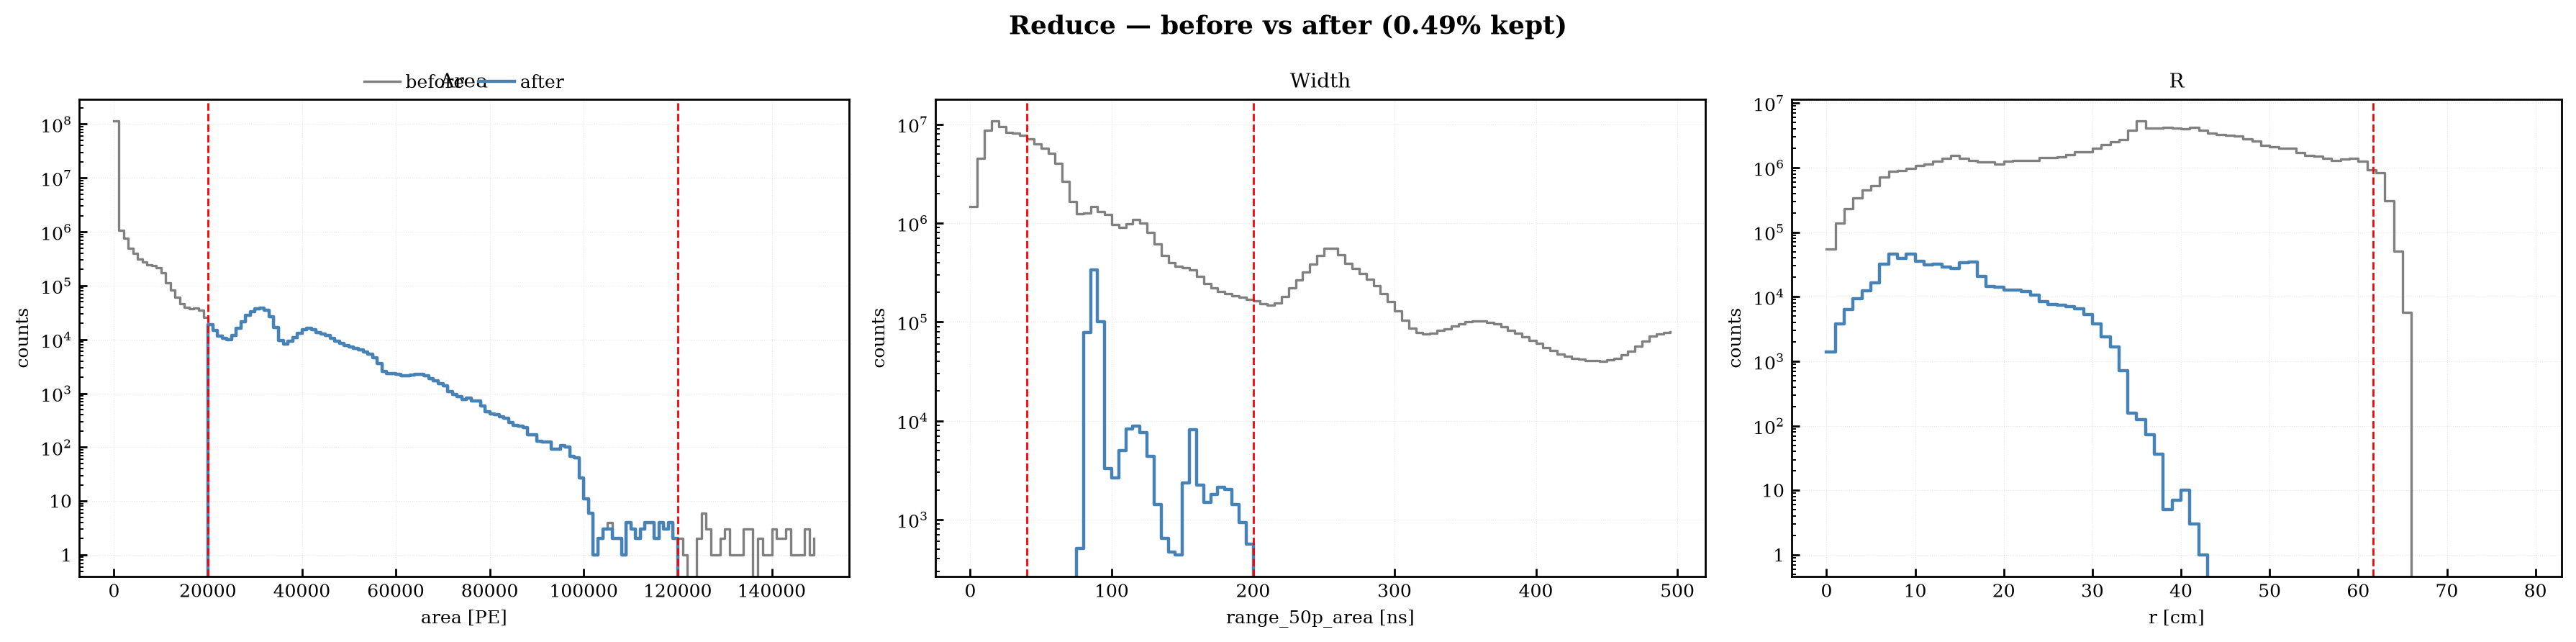

RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

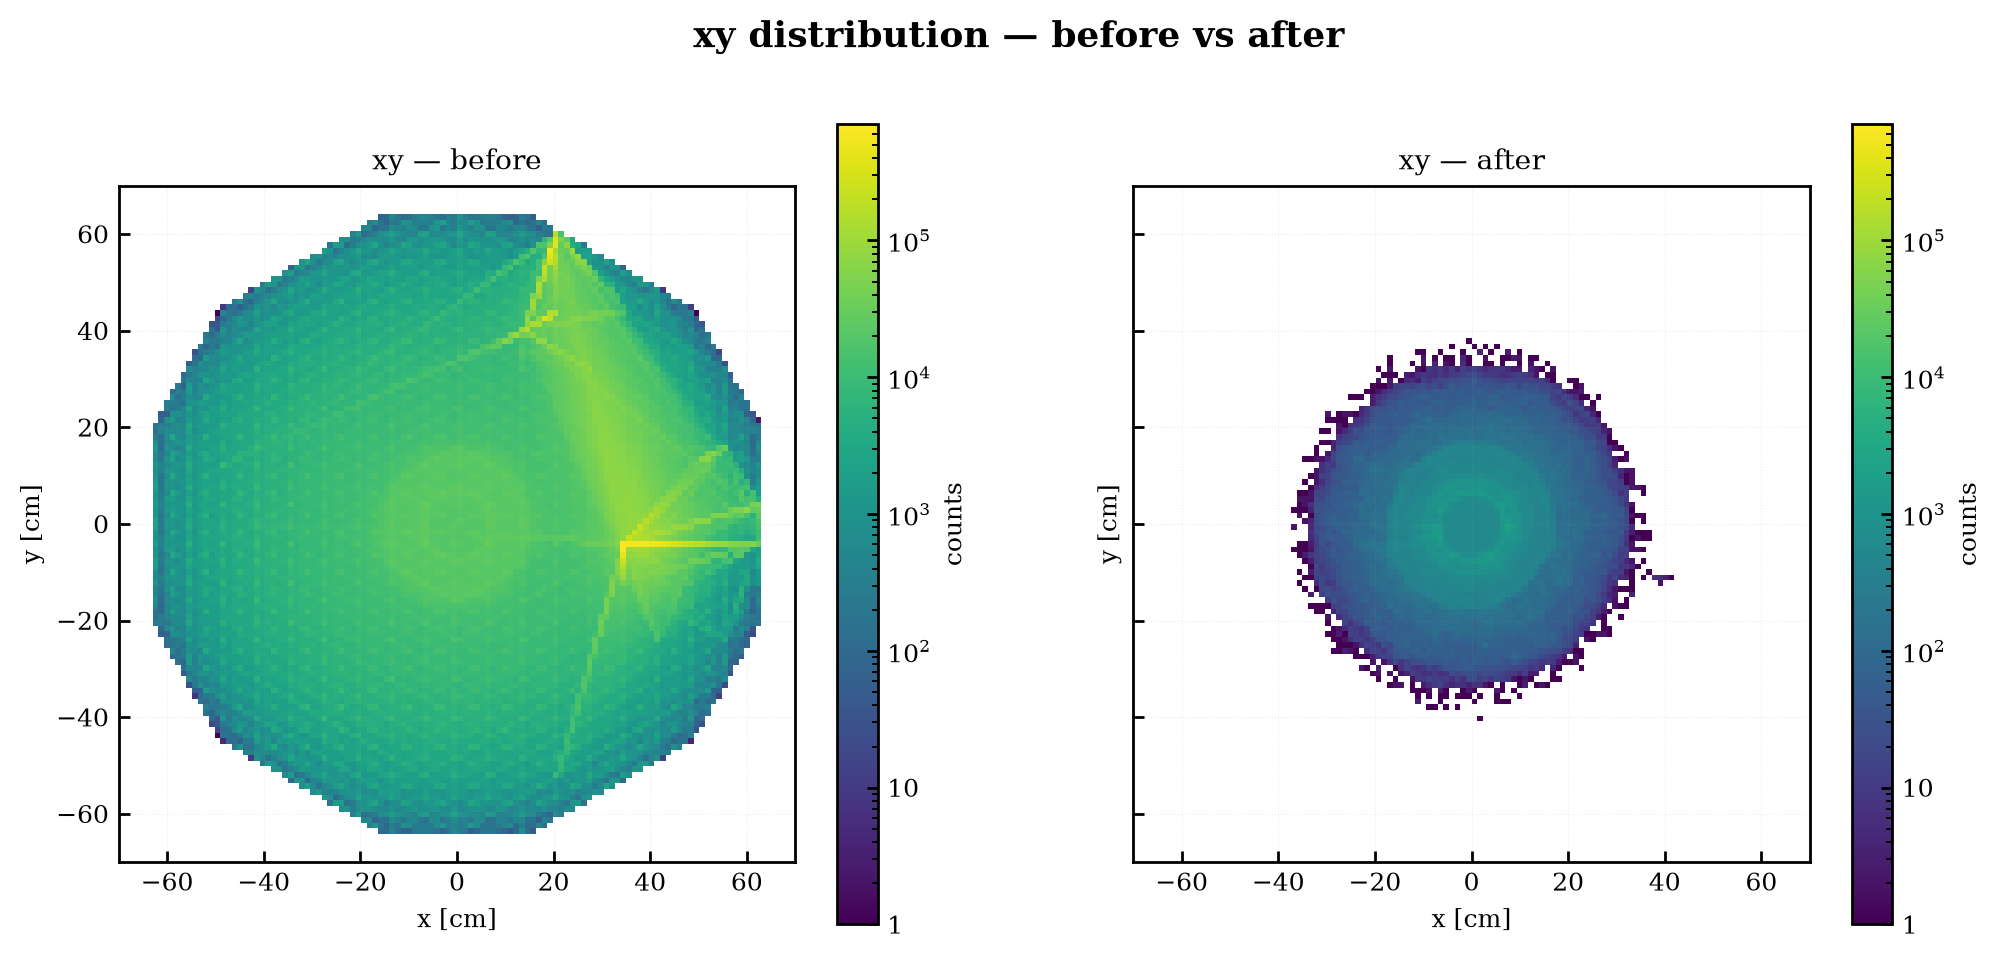

In [18]:
# ============================================================
# REDUCE — run + before/after diagnostics
# ============================================================
stats = reduce_parquet(
    SRC, OUT,
    cutoff_date=CUTOFF_DATE,
    area_min=A_MIN, area_max=A_MAX,
    width_min=W_MIN, width_max=W_MAX,
    r2_max=R2_MAX,
    keep_cols=KEEP_COLS,
    chunk=CHUNK,
    overwrite=False,
)

if stats is not None:
    import matplotlib.pyplot as plt
    import matplotlib

    # ── 1D before vs after ──
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    panels = [
        ("area",  stats["edges_a"], A_MIN, A_MAX, "area [PE]"),
        ("width", stats["edges_w"], W_MIN, W_MAX, "range_50p_area [ns]"),
        ("r",     stats["edges_r"], np.sqrt(R2_MAX), None, "r [cm]"),
    ]
    for ax, (key, edges, lo, hi, xlabel) in zip(axes, panels):
        ax.step(edges[:-1], stats["before"][key], where="post",
                color="gray", lw=1.2, label="before")
        ax.step(edges[:-1], stats["after"][key], where="post",
                color="steelblue", lw=1.6, label="after")
        ax.set_yscale("log")
        ax.axvline(lo, color="red", ls="--", lw=1)
        if hi is not None:
            ax.axvline(hi, color="red", ls="--", lw=1)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("counts")
        ax.set_title(key.capitalize())
        ax.grid(True, alpha=0.25)
    axes[0].legend(fontsize=9)
    fig.suptitle("Reduce — before vs after (%.2f%% kept)" % (100 * stats["efficiency"]),
                 fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

    # ── xy before vs after ──
    xy = stats["xy_edges"]
    vmax = max(1.0, float(max(stats["before"]["xy"].max(), stats["after"]["xy"].max())))
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
    for ax, title, h in [(axes[0], "before", stats["before"]["xy"]),
                         (axes[1], "after",  stats["after"]["xy"])]:
        im = ax.imshow(h.T, origin="lower",
                       extent=[xy[0], xy[-1], xy[0], xy[-1]],
                       aspect="equal", cmap="viridis",
                       norm=matplotlib.colors.LogNorm(vmin=1, vmax=vmax))
        ax.set_xlabel("x [cm]"); ax.set_ylabel("y [cm]")
        ax.set_title("xy — %s" % title)
        ax.grid(True, alpha=0.2)
        plt.colorbar(im, ax=ax, label="counts")
    fig.suptitle("xy distribution — before vs after", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
